# M113 — Préparation, arbre de décision et sélection

**Tâche 1 · Charaf Eddine Ifrinchaou · Master IDIA, FST Tanger**

Nous préparons les données UCI, construisons un arbre CART avec NumPy/Pandas, comparons la complexité des arbres et sélectionnons les entrées des tâches 2 et 3.

Exécuter toutes les cellules depuis la racine du dépôt. Le fichier brut est inclus pour permettre une exécution hors ligne. Le notebook reconstruit `shared/`, les résultats et `rapport_partie1.md`.

Le protocole du groupe utilise environ 60 % entraînement, 20 % validation et 20 % test, avec une graine de 42. Nous choisissons les paramètres sur validation. Le test est exporté pour les collègues et reste réservé à leurs évaluations finales.

[Données UCI et dictionnaire](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) · [Article décrivant les données](https://doi.org/10.3390/data7110146)

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import io
import json
import platform
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
CLASSES = ["Dropout", "Enrolled", "Graduate"]
ROOT = Path.cwd()
RAW = ROOT / "data" / "raw" / "data.csv"
RESULTS = ROOT / "results" / "task1"
FIGURES = RESULTS / "figures"
SHARED = ROOT / "shared"
DATA_URL = "https://archive.ics.uci.edu/static/public/697/predict%2Bstudents%2Bdropout%2Band%2Bacademic%2Bsuccess.zip"
SOURCE_URL = "https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success"
for directory in [RAW.parent, RESULTS, FIGURES, SHARED]:
    directory.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Racine du projet", ROOT)

Racine du projet /workspace/scratch/19faa5b49288/student-dropout-prediction


## 1. Lecture et contrôle des données

Chaque ligne représente un étudiant. Nous conservons les noms UCI, en supprimant les espaces et tabulations autour des en-têtes. L'identifiant `row_id` correspond à la position initiale dans le CSV. Il sert uniquement aux jointures.

In [2]:
if not RAW.exists():
    with urllib.request.urlopen(DATA_URL, timeout=60) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    RAW.write_bytes(archive.read("data.csv"))

raw_sha256 = hashlib.sha256(RAW.read_bytes()).hexdigest()
data = pd.read_csv(RAW, sep=";")
original_columns = data.columns.tolist()
data.columns = data.columns.str.strip()
assert data.columns.is_unique
data.index = pd.Index(np.arange(len(data)), name="row_id")
assert set(data["Target"].unique()) == set(CLASSES)
missing_count = int(data.isna().sum().sum())
duplicate_count = int(data.duplicated().sum())
print("Dimensions", data.shape)
print("Valeurs manquantes", missing_count, "| Lignes dupliquées", duplicate_count)
assert missing_count == 0, "La source a changé : définir une imputation apprise sur train."
assert duplicate_count == 0, "La source a changé : vérifier les doublons avant le découpage."
assert data.shape == (4424, 37), "Vérifier la version du jeu UCI avant de poursuivre."
assert np.isfinite(data.drop(columns="Target").to_numpy(dtype=float)).all()

class_counts = data["Target"].value_counts().reindex(CLASSES)
display(class_counts.rename("effectif").to_frame())
display(data.head())
data.describe().T.to_csv(RESULTS / "descriptive_statistics.csv", index_label="variable")

Dimensions (4424, 37)
Valeurs manquantes 0 | Lignes dupliquées 0


,effectif
Target,
Dropout,1421
Enrolled,794
Graduate,2209


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
row_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


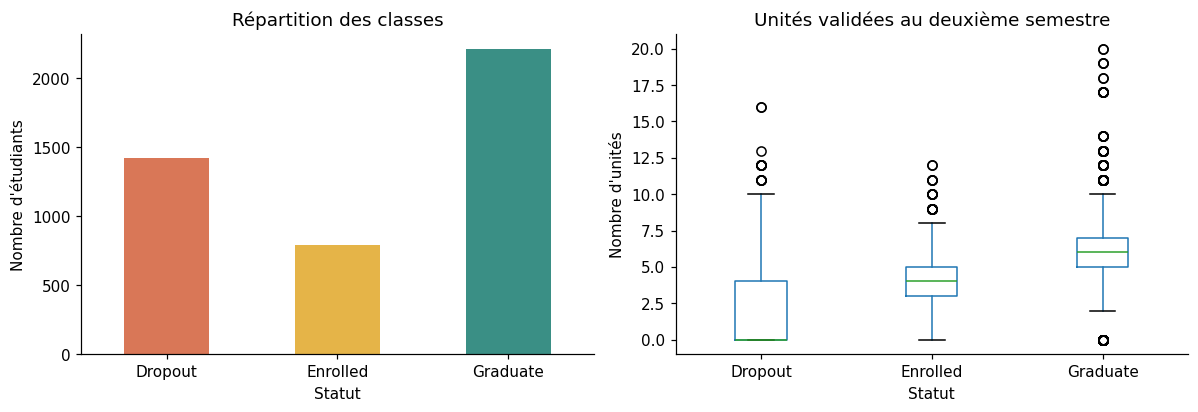

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
class_counts.plot.bar(ax=axes[0], color=["#d97757", "#e5b448", "#3a8f85"], rot=0)
axes[0].set(title="Répartition des classes", ylabel="Nombre d'étudiants", xlabel="Statut")
data.boxplot(column="Curricular units 2nd sem (approved)", by="Target", ax=axes[1], grid=False)
axes[1].set(title="Unités validées au deuxième semestre", xlabel="Statut", ylabel="Nombre d'unités")
fig.suptitle("")
fig.tight_layout()
fig.savefig(FIGURES / "description_donnees.png", bbox_inches="tight")
plt.show()

## 2. Découpage stratifié et encodage

Nous mélangeons les identifiants séparément dans chaque classe avec `default_rng(42)`, puis prenons 60 % pour train et 20 % pour validation, arrondis à l'entier inférieur. Le reste constitue le test. L'affectation sauvegardée fait référence pour les trois membres.

Les codes de filière, nationalité, profession et diplôme représentent des catégories. Le one-hot évite d'introduire une distance numérique arbitraire entre ces codes. Les variables binaires restent en 0/1. Les notes, quantités, âge, indicateurs économiques et ordre de candidature conservent leurs valeurs numériques. Le schéma est appris sur train. Une catégorie absente de train produit des zéros dans les colonnes one-hot de sa variable, et son occurrence est comptabilisée.

L'arbre utilise les valeurs avant standardisation. Les collègues ajusteront leur standardisation sur train. [Dictionnaire UCI](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success)

In [4]:
rng = np.random.default_rng(SEED)
split_ids = {name: [] for name in ["train", "val", "test"]}
for label in CLASSES:
    ids = rng.permutation(data.index[data["Target"].eq(label)].to_numpy())
    n_train, n_val = int(0.6 * len(ids)), int(0.2 * len(ids))
    split_ids["train"].extend(ids[:n_train].tolist())
    split_ids["val"].extend(ids[n_train:n_train + n_val].tolist())
    split_ids["test"].extend(ids[n_train + n_val:].tolist())

labels = data[["Target"]].copy()
labels["split"] = ""
for name, ids in split_ids.items():
    split_ids[name] = sorted(ids)
    labels.loc[ids, "split"] = name
labels = labels[["split", "Target"]]
assert labels["split"].ne("").all()
split_table = pd.crosstab(labels["split"], labels["Target"]).reindex(index=["train", "val", "test"], columns=CLASSES)
assert (split_table > 0).all().all()
display(split_table)

categorical_columns = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]
binary_columns = [
    "Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
    "Tuition fees up to date", "Gender", "Scholarship holder", "International",
]
raw_features = data.drop(columns="Target")
numeric_columns = [column for column in raw_features if column not in categorical_columns]
assert set(categorical_columns + binary_columns).issubset(raw_features.columns)
categories = {
    column: sorted(raw_features.loc[split_ids["train"], column].unique().tolist())
    for column in categorical_columns
}

def encode_features(frame):
    encoded = {column: frame[column].astype(float) for column in numeric_columns}
    for column, values in categories.items():
        for value in values:
            encoded[f"{column}__{value}"] = frame[column].eq(value).astype(float)
    return pd.DataFrame(encoded, index=frame.index)

features_by_split = {name: encode_features(raw_features.loc[ids]) for name, ids in split_ids.items()}
target_by_split = {
    name: pd.Categorical(labels.loc[ids, "Target"], categories=CLASSES).codes.astype(int)
    for name, ids in split_ids.items()
}
mapping_rows = [
    {"feature": column, "source_column": column,
     "kind": "binary" if column in binary_columns else "numeric", "category": ""}
    for column in numeric_columns
]
for column, values in categories.items():
    mapping_rows.extend({"feature": f"{column}__{value}", "source_column": column,
                         "kind": "one_hot", "category": value} for value in values)
feature_mapping = pd.DataFrame(mapping_rows)
unknown_categories = {
    name: {column: int((~raw_features.loc[ids, column].isin(values)).sum())
           for column, values in categories.items()}
    for name, ids in split_ids.items()
}
print("Nombre de caractéristiques encodées", features_by_split["train"].shape[1])
print("Occurrences de catégories absentes de train", unknown_categories)

Nombre de caractéristiques encodées 225
Occurrences de catégories absentes de train {'train': {'Marital status': 0, 'Application mode': 0, 'Course': 0, 'Previous qualification': 0, 'Nacionality': 0, "Mother's qualification": 0, "Father's qualification": 0, "Mother's occupation": 0, "Father's occupation": 0}, 'val': {'Marital status': 0, 'Application mode': 0, 'Course': 0, 'Previous qualification': 0, 'Nacionality': 4, "Mother's qualification": 2, "Father's qualification": 3, "Mother's occupation": 3, "Father's occupation": 3}, 'test': {'Marital status': 0, 'Application mode': 1, 'Course': 0, 'Previous qualification': 0, 'Nacionality': 1, "Mother's qualification": 3, "Father's qualification": 1, "Mother's occupation": 2, "Father's occupation": 2}}


Target,Dropout,Enrolled,Graduate
split,,,
train,852,476,1325
val,284,158,441
test,285,160,443


## 3. Arbre CART avec NumPy

Pour un nœud contenant des proportions de classes $p_c$, l'impureté vaut $G = 1-\sum_c p_c^2$. Nous choisissons la coupure qui maximise

$$\Delta G = G_{parent} - \frac{n_g}{n}G_g - \frac{n_d}{n}G_d.$$

Les seuils sont les milieux de valeurs distinctes consécutives. Les effectifs cumulés permettent d'évaluer les coupures sans recalculer chaque sous-tableau. Les ex æquo sont résolus par l'ordre des colonnes puis des seuils. Une feuille prédit sa classe majoritaire, avec l'ordre des classes comme départage.

L'importance d'une colonne additionne $(n_{nœud}/n_{train})\Delta G$ pour ses coupures. Les importances sont ensuite normalisées. Elles décrivent cet arbre et peuvent être partagées entre variables corrélées.

In [5]:
class DecisionTreeNumpy:
    """Arbre binaire de classification, critère de Gini, sans scikit-learn."""

    def __init__(self, max_depth=None, min_samples_leaf=1, min_gain=1e-12):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_gain = min_gain

    def fit(self, X, y):
        values = np.asarray(X, dtype=float)
        target = np.asarray(y)
        if values.ndim != 2 or len(values) == 0 or values.shape[1] == 0:
            raise ValueError("X doit être une matrice non vide.")
        if target.ndim != 1 or len(target) != len(values) or not np.isfinite(values).all():
            raise ValueError("Vérifier les dimensions de y et les valeurs finies de X.")
        if self.min_samples_leaf < 1 or (self.max_depth is not None and self.max_depth < 0):
            raise ValueError("Profondeur >= 0 et taille minimale de feuille >= 1.")
        self.feature_names_in_ = list(X.columns) if isinstance(X, pd.DataFrame) else None
        self.classes_, encoded = np.unique(target, return_inverse=True)
        self.n_classes_ = len(self.classes_)
        self.n_features_in_ = values.shape[1]
        self.n_train_ = len(values)
        self.feature_importances_ = np.zeros(self.n_features_in_)
        self.node_count_ = 0
        self.depth_ = 0
        self.root_ = self._grow(values, encoded, depth=0)
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        return self

    def _grow(self, X, y, depth):
        counts = np.bincount(y, minlength=self.n_classes_)
        impurity = 1.0 - np.sum((counts / len(y)) ** 2)
        node = {"prediction": int(np.argmax(counts)), "counts": counts.tolist(),
                "samples": len(y), "gini": float(impurity)}
        self.node_count_ += 1
        self.depth_ = max(self.depth_, depth)
        depth_limit = self.max_depth is not None and depth >= self.max_depth
        if impurity <= 1e-12 or depth_limit or len(y) < 2 * self.min_samples_leaf:
            return node

        best_gain = self.min_gain
        best_split = None
        for feature in range(X.shape[1]):
            order = np.argsort(X[:, feature], kind="stable")
            sorted_values = X[order, feature]
            positions = np.arange(1, len(y))
            valid = ((sorted_values[:-1] < sorted_values[1:])
                     & (positions >= self.min_samples_leaf)
                     & (len(y) - positions >= self.min_samples_leaf))
            positions = positions[valid]
            if len(positions) == 0:
                continue
            cumulative = np.cumsum(np.eye(self.n_classes_)[y[order]], axis=0)
            left_counts = cumulative[positions - 1]
            right_counts = counts - left_counts
            left_gini = 1.0 - np.sum((left_counts / positions[:, None]) ** 2, axis=1)
            right_sizes = len(y) - positions
            right_gini = 1.0 - np.sum((right_counts / right_sizes[:, None]) ** 2, axis=1)
            gains = impurity - (positions * left_gini + right_sizes * right_gini) / len(y)
            index = int(np.argmax(gains))
            gain = float(gains[index])
            if gain > best_gain + 1e-14:
                position = positions[index]
                lower, upper = sorted_values[position - 1], sorted_values[position]
                threshold = lower / 2.0 + upper / 2.0
                # Garantir une coupure valide même avec des flottants très proches.
                if threshold >= upper:
                    threshold = lower
                best_gain = gain
                best_split = (feature, float(threshold))

        if best_split is None:
            return node
        feature, threshold = best_split
        left_mask = X[:, feature] <= threshold
        self.feature_importances_[feature] += len(y) / self.n_train_ * best_gain
        node.update({"feature": feature, "threshold": threshold, "gain": best_gain,
                     "left": self._grow(X[left_mask], y[left_mask], depth + 1),
                     "right": self._grow(X[~left_mask], y[~left_mask], depth + 1)})
        return node

    def predict(self, X):
        if not hasattr(self, "root_"):
            raise ValueError("Appeler fit avant predict.")
        if isinstance(X, pd.DataFrame) and self.feature_names_in_ is not None:
            if list(X.columns) != self.feature_names_in_:
                raise ValueError("Les colonnes et leur ordre doivent correspondre à train.")
        values = np.asarray(X, dtype=float)
        if values.ndim != 2 or values.shape[1] != self.n_features_in_ or not np.isfinite(values).all():
            raise ValueError("Dimensions ou valeurs de X incorrectes.")
        predictions = []
        for row in values:
            node = self.root_
            while "feature" in node:
                node = node["left"] if row[node["feature"]] <= node["threshold"] else node["right"]
            predictions.append(node["prediction"])
        return self.classes_[np.asarray(predictions, dtype=int)]


def classification_metrics(y_true, y_pred, n_classes=3):
    matrix = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(matrix, (np.asarray(y_true, dtype=int), np.asarray(y_pred, dtype=int)), 1)
    true_positive = np.diag(matrix)
    denominator = matrix.sum(axis=0) + matrix.sum(axis=1)
    f1 = np.divide(2 * true_positive, denominator, out=np.zeros(n_classes), where=denominator > 0)
    return {"accuracy": float(true_positive.sum() / matrix.sum()),
            "f1_macro": float(f1.mean()), "f1_per_class": f1, "confusion_matrix": matrix}

## 4. Vérifications sur des exemples contrôlés

Ces tests vérifient une séparation connue, un problème à trois classes, un nœud pur, une colonne constante, la taille minimale des feuilles et le calcul du F1. Ils détectent des erreurs avant l'utilisation des données réelles.

In [6]:
small_X = np.array([[0.], [1.], [2.], [3.]])
small_y = np.array([0, 0, 1, 1])
small_tree = DecisionTreeNumpy().fit(small_X, small_y)
assert small_tree.root_["threshold"] == 1.5
assert np.array_equal(small_tree.predict(small_X), small_y)
assert np.allclose(small_tree.feature_importances_, [1.0])
assert np.isclose(small_tree.root_["gain"], 0.5)

multi_X = np.arange(6).reshape(-1, 1)
multi_y = np.array([0, 0, 1, 1, 2, 2])
multi_tree = DecisionTreeNumpy().fit(multi_X, multi_y)
assert np.array_equal(multi_tree.predict(multi_X), multi_y)
pure_tree = DecisionTreeNumpy().fit(small_X, np.zeros(4, dtype=int))
assert pure_tree.node_count_ == 1 and pure_tree.feature_importances_.sum() == 0
constant_tree = DecisionTreeNumpy().fit(np.ones((4, 1)), small_y)
assert constant_tree.node_count_ == 1
assert np.array_equal(constant_tree.predict(np.ones((2, 1))), [0, 0])
limited_tree = DecisionTreeNumpy(min_samples_leaf=3).fit(small_X, small_y)
assert limited_tree.node_count_ == 1
assert np.isclose(classification_metrics([0, 1, 2], [0, 0, 2])["f1_macro"], 5 / 9)

def leaf_sizes(node):
    if "feature" not in node:
        return [node["samples"]]
    return leaf_sizes(node["left"]) + leaf_sizes(node["right"])

leaf_tree = DecisionTreeNumpy(min_samples_leaf=2).fit(multi_X, multi_y)
assert min(leaf_sizes(leaf_tree.root_)) >= 2
print("Vérifications de l'arbre et des métriques réussies.")

Vérifications de l'arbre et des métriques réussies.


## 5. Comparaison et choix sur validation

Le modèle de base peut se développer jusqu'à des feuilles de taille 1. L'amélioration étudiée est le pré-élagage, en limitant la profondeur et la taille minimale des feuilles. Nous comparons neuf réglages. Le F1 macro donne le même poids à chaque classe.

La sélection du modèle utilise le meilleur F1 macro de validation. En cas d'égalité, nous retenons le plus petit arbre, puis le premier réglage essayé. Une seule partition de validation fournit une estimation qui dépend du découpage.

In [7]:
tree_X_train = features_by_split["train"]
tree_X_val = features_by_split["val"]
tree_y_train = target_by_split["train"]
tree_y_val = target_by_split["val"]
configurations = [(None, 1)] + [(depth, leaf) for depth in [3, 5, 8] for leaf in [5, 10, 20]]
tree_models = []
comparison_rows = []
for depth, leaf in configurations:
    tree_model = DecisionTreeNumpy(max_depth=depth, min_samples_leaf=leaf)
    started = perf_counter()
    tree_model.fit(tree_X_train, tree_y_train)
    elapsed = perf_counter() - started
    train_scores = classification_metrics(tree_y_train, tree_model.predict(tree_X_train))
    val_scores = classification_metrics(tree_y_val, tree_model.predict(tree_X_val))
    comparison_rows.append({
        "model_id": len(tree_models), "variant": "base" if depth is None else "pre_elagage",
        "max_depth": "illimitee" if depth is None else str(depth), "min_samples_leaf": leaf,
        "actual_depth": tree_model.depth_, "nodes": tree_model.node_count_,
        "train_f1_macro": train_scores["f1_macro"], "val_f1_macro": val_scores["f1_macro"],
        "train_accuracy": train_scores["accuracy"], "val_accuracy": val_scores["accuracy"],
        "training_seconds": elapsed,
    })
    tree_models.append(tree_model)

comparison = pd.DataFrame(comparison_rows)
best_index = int(comparison.sort_values(["val_f1_macro", "nodes", "model_id"],
                                      ascending=[False, True, True]).iloc[0]["model_id"])
tree_best = tree_models[best_index]
comparison["retained"] = comparison["model_id"].eq(best_index)
comparison.to_csv(RESULTS / "tree_comparison.csv", index=False)
display(comparison.round(4))
print("Modèle retenu", best_index)

Modèle retenu 7


,model_id,variant,max_depth,min_samples_leaf,actual_depth,nodes,train_f1_macro,val_f1_macro,train_accuracy,val_accuracy,training_seconds,retained
0,0,base,illimitee,1,28,985,1.0000,0.5932,1.0000,0.6557,2.4322,False
1,1,pre_elagage,3,5,3,15,0.6323,0.6027,0.7361,0.7135,0.1203,False
2,2,pre_elagage,3,10,3,15,0.6323,0.6027,0.7361,0.7135,0.1064,False
3,3,pre_elagage,3,20,3,15,0.6323,0.6027,0.7361,0.7135,0.0948,False
4,4,pre_elagage,5,5,5,59,0.6915,0.6382,0.7712,0.7259,0.2400,False
5,5,pre_elagage,5,10,5,59,0.6849,0.6334,0.7663,0.7225,0.2256,False
6,6,pre_elagage,5,20,5,53,0.6737,0.6218,0.7610,0.7169,0.2294,False
7,7,pre_elagage,8,5,8,199,0.7664,0.6738,0.8142,0.7429,0.5605,True
8,8,pre_elagage,8,10,8,155,0.7464,0.6614,0.8014,0.7327,0.4334,False
9,9,pre_elagage,8,20,8,121,0.7211,0.6403,0.7814,0.7225,0.3267,False


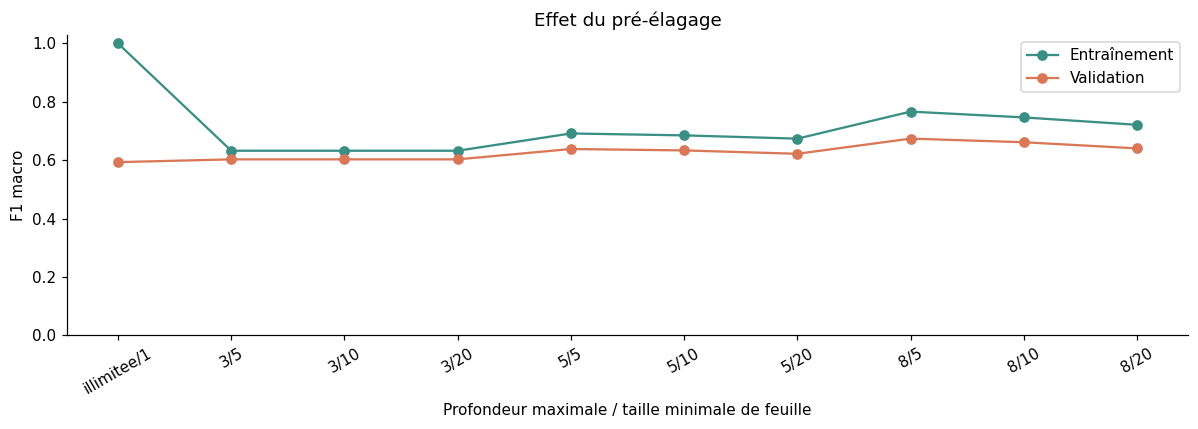

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))
positions = np.arange(len(comparison))
ax.plot(positions, comparison["train_f1_macro"], "o-", label="Entraînement", color="#3a8f85")
ax.plot(positions, comparison["val_f1_macro"], "o-", label="Validation", color="#d97757")
ax.set_xticks(positions, [f"{row.max_depth}/{row.min_samples_leaf}" for row in comparison.itertuples()], rotation=30)
ax.set(xlabel="Profondeur maximale / taille minimale de feuille", ylabel="F1 macro", ylim=(0, 1.03), title="Effet du pré-élagage")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "comparaison_arbres.png", bbox_inches="tight")
plt.show()

## 6. Sélection des caractéristiques

Nous retenons le plus petit ensemble de colonnes atteignant 90 % de l'importance cumulée de l'arbre choisi. Le seuil de 90 % vient de la convention du groupe. Il est fixé avant les résultats. Les valeurs exportées gardent leurs unités avant standardisation.

Première coupure Curricular units 2nd sem (approved) <= 3.5
Colonnes retenues ['Curricular units 2nd sem (approved)', 'Tuition fees up to date', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (approved)', 'Age at enrollment', 'Curricular units 2nd sem (evaluations)', 'Curricular units 1st sem (evaluations)', 'Curricular units 2nd sem (grade)', 'Admission grade', 'Curricular units 2nd sem (enrolled)', 'Curricular units 1st sem (grade)']


,feature,importance,cumulative_importance,selected
0,Curricular units 2nd sem (approved),0.584824,0.584824,True
1,Tuition fees up to date,0.080243,0.665068,True
2,Curricular units 1st sem (enrolled),0.042686,0.707754,True
3,Curricular units 1st sem (approved),0.036020,0.743774,True
4,Age at enrollment,0.034273,0.778047,True
5,Curricular units 2nd sem (evaluations),0.031827,0.809873,True
6,Curricular units 1st sem (evaluations),0.025201,0.835074,True
7,Curricular units 2nd sem (grade),0.022339,0.857413,True
8,Admission grade,0.017279,0.874692,True
9,Curricular units 2nd sem (enrolled),0.016278,0.890969,True


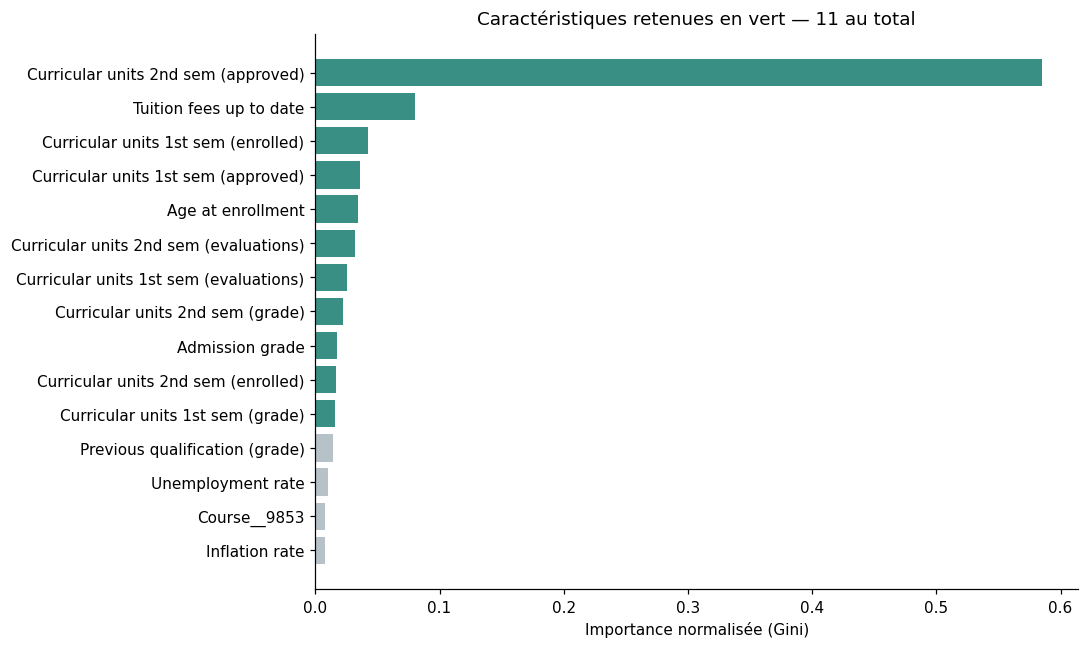

In [9]:
importances = pd.DataFrame({"feature": tree_X_train.columns, "importance": tree_best.feature_importances_})
importances = importances.sort_values("importance", ascending=False, kind="stable").reset_index(drop=True)
assert importances["importance"].sum() > 0, "Aucune coupure utile : vérifier l'arbre et les données."
importances["cumulative_importance"] = importances["importance"].cumsum()
selected_count = int(np.searchsorted(importances["cumulative_importance"].to_numpy(), 0.90) + 1)
selected_features = importances.head(selected_count)["feature"].tolist()
importances["selected"] = importances["feature"].isin(selected_features)
importances.to_csv(RESULTS / "feature_importances.csv", index=False)
display(importances.head(max(selected_count, 12)))

fig, ax = plt.subplots(figsize=(10, 6))
top = importances.head(15).iloc[::-1]
ax.barh(top["feature"], top["importance"], color=["#3a8f85" if value else "#b7c2c8" for value in top["selected"]])
ax.set(xlabel="Importance normalisée (Gini)", title=f"Caractéristiques retenues en vert — {selected_count} au total")
fig.tight_layout()
fig.savefig(FIGURES / "importances_variables.png", bbox_inches="tight")
plt.show()

root_feature = tree_X_train.columns[tree_best.root_["feature"]]
print("Première coupure", root_feature, "<=", tree_best.root_["threshold"])
print("Colonnes retenues", selected_features)

## 7. Exports communs et vérification du contrat

Le dossier `shared/` contient les identifiants, l'affectation des splits, le schéma et les données sélectionnées. Un identifiant de contenu permet de reconnaître une régénération identique. Une modification des données ou des réglages augmente la version du contrat. Chaque collègue charge `row_id` comme index et joint les cibles par cet index.

In [10]:
def write_json(path, content):
    path.write_text(json.dumps(content, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

preprocessing = {
    "column_renaming": {old: old.strip() for old in original_columns if old != old.strip()},
    "categorical_columns": categorical_columns, "numeric_columns": numeric_columns,
    "binary_columns": binary_columns, "categories": categories,
    "imputation": None, "missing_values_observed": missing_count,
    "unknown_category_policy": "all_zero_for_the_source_column",
    "unknown_category_counts": unknown_categories,
    "standardization": "none; fit separately on train in tasks 2 and 3",
    "encoded_features": tree_X_train.columns.tolist(),
}
selection_parameters = {"threshold": 0.90, "max_depth": tree_best.max_depth,
                        "min_samples_leaf": tree_best.min_samples_leaf, "min_gain": tree_best.min_gain}
content_definition = {"raw_sha256": raw_sha256, "seed": SEED, "splits": split_ids,
                      "preprocessing": preprocessing, "features": selected_features,
                      "selection_parameters": selection_parameters}
content_fingerprint = hashlib.sha256(json.dumps(content_definition, sort_keys=True).encode()).hexdigest()
contract_version = 1
previous_metadata_path = SHARED / "metadata.json"
if previous_metadata_path.exists():
    previous = json.loads(previous_metadata_path.read_text(encoding="utf-8"))
    contract_version = int(previous["contract_version"])
    if previous.get("content_fingerprint") != content_fingerprint:
        contract_version += 1

metadata = {
    "contract_version": contract_version, "content_fingerprint": content_fingerprint,
    "source": SOURCE_URL, "raw_sha256": raw_sha256, "seed": SEED,
    "split_method": "per-class default_rng(42) permutation, floor 60%, floor 20%, remainder test; row_id sorted",
    "split_counts": {name: len(ids) for name, ids in split_ids.items()},
    "class_order": CLASSES, "class_to_int": {label: index for index, label in enumerate(CLASSES)},
    "class_counts_by_split": split_table.to_dict(orient="index"),
    "selected_feature_count": selected_count,
    "prediction_context": "includes first- and second-semester information; retrospective classification",
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
}
selected_definition = {"contract_version": contract_version, "features": selected_features,
                      "selection_method": "cumulative_normalized_weighted_gini_decrease",
                      "selection_parameters": selection_parameters}

# Préparer et vérifier tous les tableaux avant d'écrire les exports.
selected_tables = {name: frame.loc[:, selected_features] for name, frame in features_by_split.items()}
all_ids = set()
for name, frame in selected_tables.items():
    assert frame.index.is_unique and frame.index.name == "row_id"
    assert list(frame.columns) == selected_features
    assert np.isfinite(frame.to_numpy()).all()
    assert not all_ids.intersection(frame.index)
    all_ids.update(frame.index)
    assert labels.loc[frame.index, "split"].eq(name).all()
assert all_ids == set(data.index)
assert feature_mapping["feature"].is_unique
assert set(selected_features).issubset(feature_mapping["feature"])

for name, frame in selected_tables.items():
    frame.to_csv(SHARED / f"X_{name}.csv", index=True)
labels.to_csv(SHARED / "labels.csv", index=True)
data.to_csv(SHARED / "data_clean.csv", index=True)
feature_mapping.to_csv(SHARED / "feature_mapping.csv", index=False)
write_json(SHARED / "preprocessing.json", preprocessing)
write_json(SHARED / "selected_features.json", selected_definition)
write_json(RESULTS / "tree_structure.json", tree_best.root_)
write_json(SHARED / "metadata.json", metadata)

for name, expected in selected_tables.items():
    actual = pd.read_csv(SHARED / f"X_{name}.csv", index_col="row_id")
    pd.testing.assert_frame_equal(actual, expected, check_dtype=False, rtol=1e-12)
print("Contrat vérifié et exporté, version", contract_version)
display(pd.DataFrame({"split": list(selected_tables), "rows": [len(frame) for frame in selected_tables.values()],
                      "features": selected_count}))

Contrat vérifié et exporté, version 1


,split,rows,features
0,train,2653,11
1,val,883,11
2,test,888,11


## 8. Texte pour le rapport et transmission

La cellule suivante génère une contribution fondée sur les résultats de cette exécution. La synthèse bibliographique décrit l'article des auteurs. Le rapport commun devra intégrer les contributions des deux collègues.

In [11]:
def markdown_table(frame):
    header = "| " + " | ".join(map(str, frame.columns)) + " |"
    divider = "| " + " | ".join(["---"] * len(frame.columns)) + " |"
    rows = ["| " + " | ".join(map(str, row)) + " |" for row in frame.itertuples(index=False, name=None)]
    return "\n".join([header, divider] + rows)

best_row = comparison.loc[comparison["retained"]].iloc[0]
base_row = comparison.iloc[0]
report_scores = comparison[["max_depth", "min_samples_leaf", "nodes", "train_f1_macro", "val_f1_macro", "retained"]].copy()
for column in ["train_f1_macro", "val_f1_macro"]:
    report_scores[column] = report_scores[column].map(lambda value: f"{value:.4f}")
selected_report = importances.loc[importances["selected"], ["feature", "importance"]].copy()
selected_report["importance"] = selected_report["importance"].map(lambda value: f"{value:.4f}")
report = f"""# M113 — Contribution de la tâche 1

## Description des données

Le fichier UCI lu contient {len(data)} lignes, {len(raw_features.columns)} variables explicatives et la cible `Target`. Les effectifs mesurés sont {class_counts['Dropout']} Dropout, {class_counts['Enrolled']} Enrolled et {class_counts['Graduate']} Graduate. Le contrôle trouve {missing_count} valeur manquante et {duplicate_count} ligne dupliquée. Le champ d'assiduité comportait une tabulation finale supprimée des noms de colonnes. Les observations sont conservées. [1]

## Synthèse d'un travail de recherche

Realinho et ses collègues décrivent en 2022 la construction d'une base issue de données administratives et académiques de l'Institut polytechnique de Portalegre. Leur article analyse notamment le déséquilibre des classes, la multicolinéarité et l'importance des variables. Il motive ici l'usage du F1 macro et une interprétation prudente des importances. La publication décrit 35 attributs, tandis que la version UCI effectivement téléchargée fournit 36 prédicteurs. Nous documentons la version utilisée par son empreinte. Cette contribution doit être complétée par les lectures des deux autres membres. [1, 2]

## Prétraitements et protocole

Le découpage stratifié déterministe donne {len(split_ids['train'])} lignes de train, {len(split_ids['val'])} de validation et {len(split_ids['test'])} de test. Neuf variables catégorielles sont encodées selon les catégories présentes dans train. Les autres colonnes conservent leurs valeurs numériques. Cela produit {tree_X_train.shape[1]} colonnes avant sélection. Les catégories nouvelles de validation/test sont encodées à zéro pour leur variable et comptabilisées dans `preprocessing.json`. Aucun remplacement de valeurs manquantes n'est nécessaire.

La validation sert au choix de complexité de l'arbre. Aucun score de test n'est calculé dans la tâche 1. Les collègues appliqueront leur standardisation ajustée sur train. Ce découpage 60/20/20 est un choix du groupe. L'arbre choisi et les importances sont appris sur train.

## Implémentation et amélioration

L'arbre CART est implémenté avec NumPy. Il utilise Gini, des seuils entre valeurs distinctes, une construction récursive et des feuilles prédisant la classe majoritaire. Les sommes cumulées accélèrent le calcul des coupures. Le pré-élagage est étudié en comparant un arbre sans limite de profondeur à neuf combinaisons de profondeur et de taille minimale des feuilles. Les métriques sont calculées avec NumPy. Des exemples synthétiques vérifient les coupures, les cas constants/purs, le multiclasse et le F1.

## Résultats

{markdown_table(report_scores)}

L'arbre retenu a une profondeur maximale paramétrée de {best_row['max_depth']}, une taille minimale de feuille de {best_row['min_samples_leaf']} et {best_row['nodes']} nœuds. Son F1 macro vaut {best_row['train_f1_macro']:.4f} sur train et {best_row['val_f1_macro']:.4f} sur validation. Le modèle de base obtient {base_row['val_f1_macro']:.4f} sur validation. L'écart de validation du modèle retenu par rapport à la base est {best_row['val_f1_macro'] - base_row['val_f1_macro']:+.4f}.

La première coupure porte sur `{root_feature}` au seuil {tree_best.root_['threshold']:.6g}. Le seuil de 90 % d'importance cumulée retient {selected_count} colonnes, représentant {importances.head(selected_count)['importance'].sum():.2%} de l'importance.

{markdown_table(selected_report)}

![Effet du pré-élagage](results/task1/figures/comparaison_arbres.png)

![Importance des caractéristiques](results/task1/figures/importances_variables.png)

## Discussion et limites

Le gain de Gini décrit les décisions de cet arbre. Il peut favoriser des variables offrant beaucoup de coupures et répartir l'importance entre prédicteurs corrélés. La sélection à 90 % est une convention à évaluer dans les modèles suivants. Le choix de paramètres sur une seule validation reste sensible au découpage. Les classes et le contexte institutionnel limitent la généralisation à une autre population.

Les résultats du deuxième semestre sont utilisés. L'analyse est rétrospective et ne démontre pas une capacité d'alerte dès l'inscription. Les dates individuelles d'abandon ne sont pas fournies. La sélection utilisant les vraies classes, K-means travaillera ensuite dans un espace sélectionné de façon supervisée. Les groupes devront être interprétés avec cette limite.

## Conclusion de la partie

Le dossier `shared/` version {contract_version} fournit aux collègues les {selected_count} entrées retenues, les identifiants et les mêmes splits. Les étapes de classification et de clustering pourront mesurer leur pertinence pour les objectifs du projet.

## Bibliographie

1. Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). Predict Students' Dropout and Academic Success. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89. Données sous licence CC BY 4.0.
2. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting Student Dropout and Academic Success. Data, 7(11), 146. https://doi.org/10.3390/data7110146.

Empreinte SHA-256 du CSV brut — `{raw_sha256}`.
"""
(ROOT / "rapport_partie1.md").write_text(report, encoding="utf-8")
print("rapport_partie1.md généré à partir des résultats mesurés.")

rapport_partie1.md généré à partir des résultats mesurés.


## Chargement pour les collègues

Transmettre le dossier `shared/` entier. Dans les tâches 2 et 3, utiliser le chargement ci-dessous puis ajuster la standardisation sur `X_train`.

```python
from pathlib import Path
import json
import pandas as pd

shared = Path("shared")
features = json.loads((shared / "selected_features.json").read_text(encoding="utf-8"))["features"]
labels = pd.read_csv(shared / "labels.csv", index_col="row_id")
X_train = pd.read_csv(shared / "X_train.csv", index_col="row_id").loc[:, features]
y_train = labels.loc[X_train.index, "Target"]
```

Répéter le chargement avec `val` et `test` en conservant les identifiants et l'ordre des colonnes.